# 18 - Multi-well / Field Study

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/18_multiwell_field_study.ipynb)

**Part B - Petrophys Curriculum**

Single-well interpretation is where you learn the physics; **field studies** are where the
value is. This lesson scales the dynamic workflow across the **17-well Costa carbonate
field**, harmonises logs so wells can be compared fairly, and rolls the results up into a
**portfolio table** and a **cross-well summary figure**. Each Costa LAS file covers only
the **Kharaib-2 reservoir interval** of its well, so every number below describes that
interval, not the whole well.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Read a whole field with one `pp.read` call and interpret every well with one
  `pp.interpret` call, then read the run with `results.summary()`.
- Understand **multi-well log normalization** (`petrophys.preprocessing.normalization`) and why
  it is needed before cross-well comparison.
- Extract per-well reservoir metrics (net pay, average porosity, average `Sw`, an HCPV
  index) with `results.formation_summary()` into a single comparison table.
- Build **cross-well summary plots**: a ranking of the field's wells and one figure
  comparing their logs (`pp.plot(results, curves=[...])`).

## Why this matters

Wells in one field are logged by different tools, crews, and vintages, so raw curve
distributions can drift from well to well for reasons that have nothing to do with the
rock. Two jobs follow:

1. **Normalization** removes acquisition drift so a `GR` of 40 means the same clay
   content in every well - a prerequisite for pooling data or ranking wells. But the
   drift has to be *diagnosed*, not assumed: part of a shifted distribution can be real
   geology, and normalizing it away destroys signal.
2. **Field interpretation + roll-up** turns 17 separate analyses into one portfolio view:
   which wells carry the pay, how thick, how clean, how much hydrocarbon volume. That view
   drives development decisions.

### Prerequisites

Assumes the single-well interpretation concepts from Part A and the metrics they
produce (`PHIE`, `SW`, `NET_PAY`), plus formation summaries from lesson 11. The Costa
files are small (~430 samples each), so the whole field runs in seconds - no
subsampling needed.

In [2]:
import petrophys as pp
from petrophys.preprocessing.normalization import normalize_log


## 1. Load the field

`pp.list_samples("costa")` gives the 17 well names and `pp.sample(name)` resolves each
to its bundled LAS path. `pp.read` takes the list and reads every well, attaching the
bundled Costa tops (`formations_costa`): the tops table holds all 17 wells, is read once,
and each well keeps its own rows. Each file covers only the **Kharaib-2 reservoir
interval** of its well, so the tops label the logged interval `KHARAIB-2`; the per-well
summaries in Section 4 use that label. A file that cannot be read would be named in
`wells.failed`. (These files are compact, so we keep every depth sample; for a large
field you would subsample depth or process in chunks - and say so.)

In [3]:
wells = pp.read([pp.sample(name) for name in pp.list_samples("costa")],
                formations=pp.sample("formations_costa"))
wells

WellList(17 wells: HW-10, HW-24, HW-25, HW-26, HW-27, HW-28 ...)

## 2. Interpret the whole field

`pp.interpret` takes the list of wells as it is and runs the same **dynamic workflow**
on each - routing `VCL -> PHIE -> SW -> PERM` when inputs permit and setting the
net-pay flags - with the settings checked once, before any well runs. It works on
copies, so `wells` stays as read, and it keeps going when a well fails: the failure is
named in `results.failed` and in a warning. `results.summary()` gives one row per well:
status, net thickness (in the well's depth unit - feet here), the median key results
and the number of warnings.

We pass the **Costa project cutoff set** (vcl 0.30 / phie 0.10 / sw 0.60 -
deliberately tighter than the generic carbonate standard of 0.045 / 0.70,
because Kharaib porosity runs high) - the same numbers case study 3 uses to
screen this field, so the two lessons are comparable knob-for-knob - and
`lithology_domain="carbonate"`, because the domain defaults to clastic. No Rw is
passed: each Costa LAS header carries Rw and the temperature it was measured at, and
the workflow corrects that value to formation temperature (`results["HW-3"].print_trace()`
shows the decision in its `rw` step).

In [4]:
results = pp.interpret(wells, lithology_domain="carbonate",
                       vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)
results.summary().round(3)

,Well,Status,Depth unit,Net rock,Net reservoir,Net pay,Median VCL,Median PHIE,Median SW,Median PERM,Warnings
0,HW-10,interpreted,ft,190.5,152.0,10.5,0.009,0.23,1.000,2.770,3
1,HW-24,interpreted,ft,216.5,165.0,148.5,0.000,0.24,0.317,5.260,2
2,HW-25,interpreted,ft,206.5,156.0,155.0,0.000,0.26,0.098,3.000,3
3,HW-26,interpreted,ft,172.5,110.0,39.5,0.000,0.13,0.974,0.550,2
4,HW-27,interpreted,ft,203.5,164.0,0.5,0.012,0.24,1.000,1.500,4
5,HW-28,interpreted,ft,203.5,164.5,4.0,0.016,0.23,1.000,4.200,3
6,HW-29,interpreted,ft,222.5,188.5,188.5,0.000,0.31,0.078,10.430,3
7,HW-3,interpreted,ft,215.5,189.5,189.5,0.000,0.29,0.102,7.300,3
8,HW-30,interpreted,ft,240.5,210.5,206.0,0.000,0.29,0.120,7.540,3
9,HW-31,interpreted,ft,210.5,172.5,0.0,0.020,0.23,1.000,3.340,4


Every well is interpreted (`results.failed` is empty). Twelve wells carry net pay. Nine
wells read a median Sw of 1.0, the five without pay among them. Read the `Warnings`
column before the Sw: `results["HW-31"].warnings` lists a well's notes. In HW-7, HW-9,
HW-27 and HW-31 the run warns that the header Rw looks too high: the apparent water
resistivity of their clean porous rock is well below it (0.39 of it in HW-31), Archie
gives Sw above 1 there, and SW is held at 1. The headers' Rw differs from well to well
(about 50,000 to 125,000 ppm NaCl), lesson 15 takes COSTA formation water as about
200,000 ppm, and the files' own `SW_INPUT` averages below this run's Sw in every well
that has it. These wells are wet at the header Rw, but treat the Sw and net pay of the
whole table as a screening with header values; a study sets one field Rw from a water
analysis (`rw=`, `rw_meas_temp=`). The `Median PHIE` and `Median PERM` columns
read the core-corrected `PHIE_CC` and `PERM_CC` each Costa file delivers, where present:
the median core-corrected permeability runs from 0.18 to 10.43 mD across the field.

## 3. Multi-well log normalization

Before we compare wells, look at how their **GR distributions** differ. Even in the same
carbonate, the GR window shifts well to well. Some of that shift may be acquisition
drift (tool, calibration, vintage, borehole) - but verify against lithology before
normalizing. HW-26's higher GR (the bars near 70 API in the raw histogram below), for instance, is plausibly a real, more argillaceous
section; forcing every well's P5-P95 onto one common range would erase that geology.
That is the classic normalization pitfall. With that caveat stated, `normalize_log`
rescales a curve so a source window (by default the curve's own P5-P95) maps to a
target range (here 0-100), aligning the distributions.

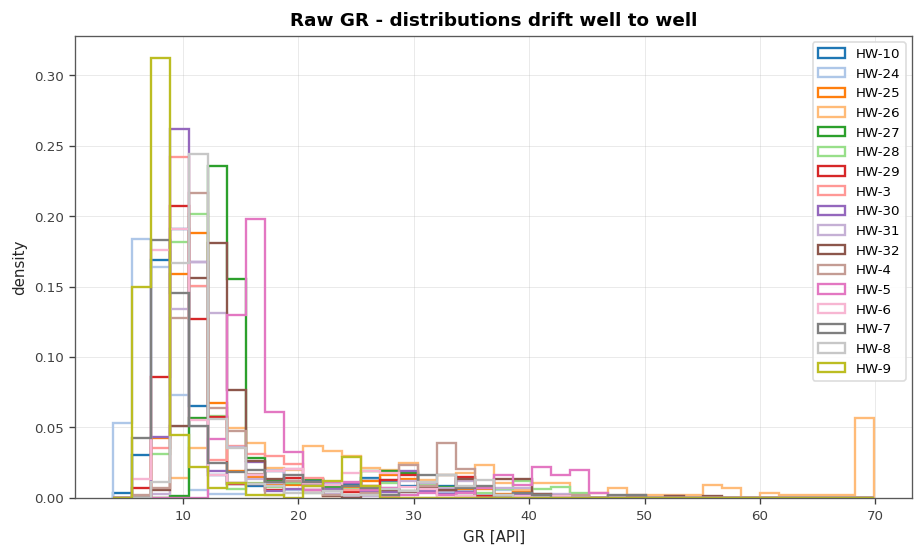

In [5]:
pp.histograms(wells, "GR", bins=40, density=True, histtype="step",
              title="Raw GR - distributions drift well to well");

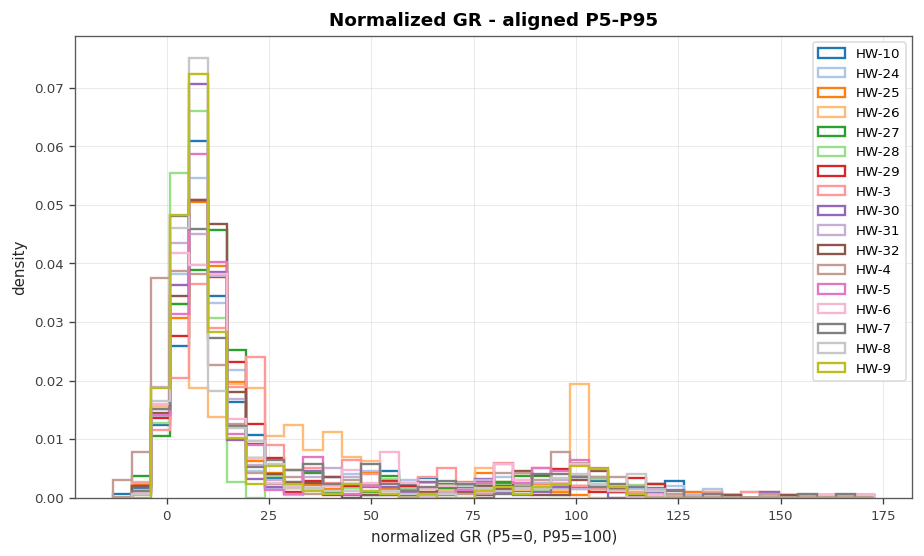

In [6]:
gr_norm = {well.name: normalize_log(well.get("GR"), log_min=0, log_max=100) for well in wells}
pp.histograms(gr_norm, bins=40, density=True, histtype="step",
              xlabel="normalized GR (P5=0, P95=100)", title="Normalized GR - aligned P5-P95");

After normalization the histograms line up: a given normalized GR reads on the same
relative scale in every well - provided the shifts we removed really were acquisition
effects. That is the precondition for pooling wells or ranking them on the same scale.

## 4. Per-well reservoir metrics

Because every well carries the `KHARAIB-2` label, `results.formation_summary()` returns
one row per well with the library's standard interval metrics (thicknesses in the
well's depth unit - feet here):

- **Gross** - the logged Kharaib-2 thickness; **Net Pay** - the thickness flagged
  `NET_PAY` (pay samples x sample step);
- **Pay/Gross** - net pay / gross;
- **Avg PHIE** - the thickness-weighted mean over the pay samples; **Avg Sw** - the
  pore-volume-weighted mean (each sample's Sw counts with its porosity and thickness);
  **Avg Perm** - a geometric mean over pay. Porosity and permeability are taken from the
  core-corrected `PHIE_CC` and `PERM_CC` each Costa file delivers - the curves the
  workflow used for Sw and pay - and, at pay samples where a file has no value for them,
  from the workflow's own `PHIE` and `PERM` (the check below shows what that does to
  `Avg Perm`);
- **HCPV** - a hydrocarbon pore-thickness index, the sum of `PHIE x (1 - Sw) x sample
  thickness` over the pay samples, equal to Avg PHIE x (1 - Avg Sw) x Net Pay (per unit area; a relative volumetric indicator, not
  a booked reserve). Wells without pay have no averages and no HCPV (NaN).

Gross is the thickness *labelled* `KHARAIB-2`. For most wells that is the whole file;
where a log continues below the Kharaib-2 base given in the tops table (HW-8 and HW-9),
the deepest samples lie outside the summary. Sorted by HCPV, the table is the field's
portfolio ranking.

In [7]:
portfolio = results.formation_summary().sort_values("HCPV", ascending=False)
portfolio[["Well", "Gross (ft)", "Net Pay (ft)", "Pay/Gross", "Avg PHIE", "Avg Sw", "Avg Perm (mD)", "HCPV"]].round(3)

,Well,Gross (ft),Net Pay (ft),Pay/Gross,Avg PHIE,Avg Sw,Avg Perm (mD),HCPV
6,HW-29,222.5,188.5,0.847,0.309,0.085,47.002,53.209
8,HW-30,240.5,206.0,0.857,0.284,0.144,13.657,50.176
7,HW-3,215.5,189.5,0.879,0.268,0.101,16.490,45.671
2,HW-25,206.5,155.0,0.751,0.254,0.092,8.151,35.696
1,HW-24,216.5,148.5,0.686,0.246,0.262,7.374,26.943
13,HW-6,208.5,141.5,0.679,0.241,0.255,10.149,25.383
10,HW-32,209.5,105.0,0.501,0.273,0.328,21.858,19.250
3,HW-26,172.5,39.5,0.229,0.157,0.426,0.995,3.572
0,HW-10,190.5,10.5,0.055,0.249,0.514,12.980,1.272
5,HW-28,203.5,4.0,0.020,0.138,0.526,1.823,0.261


### Check the permeability before using it

`Avg Perm (mD)` in the table is a geometric mean over the pay samples of the file's
core-corrected `PERM_CC`, with the workflow's own default carbonate permeability `PERM`
standing in at pay samples where `PERM_CC` has no value. That `PERM` deserves a check: it is a Coates-type
transform whose irreducible saturation is taken from the low end of the computed Sw,
and its output is clipped at 10,000 mD. Over the pay samples of the top-ranked well,
HW-29, the interpreted well holds both curves side by side:

In [8]:
results["HW-29"].well.to_dataframe(curves=["NET_PAY", "PERM", "PERM_CC"], include_depth=False).query("NET_PAY > 0.5").describe().round(1)

,NET_PAY,PERM,PERM_CC
count,377.0,377.0,318.0
mean,1.0,8630.9,54.0
std,0.0,2605.6,115.2
min,1.0,0.2,0.1
25%,1.0,8392.1,7.7
50%,1.0,10000.0,11.9
75%,1.0,10000.0,33.5
max,1.0,10000.0,722.2


Over HW-29's 377 pay samples the median `PERM` is the 10,000 mD clip (more than half
the pay sits there), against a median `PERM_CC` of 11.9 mD: nearly three orders of
magnitude apart. `PERM_CC` has a value at 318 of the 377 pay samples; the other 59
enter the portfolio's `Avg Perm` with `PERM`, which lifts HW-29's average from 18.0 mD
(`PERM_CC` alone) to the 47.0 mD of the table. HW-3, HW-25, HW-30 and HW-32 are lifted
the same way. The workflow's `PERM` is therefore **uncalibrated** and in the
top-ranked well mostly reflects the clip, not the rock; do not
rank flow capacity with it. Net pay, PHIE and Sw do not depend on `PERM`. For a
permeability comparison, use the files' `PERM_CC` alone
or a transform calibrated to core.

### Field roll-up

Summing across the field gives the headline numbers. The portfolio table shows how
concentrated the value is: twelve wells carry some net pay, but only nine have at
least 10 ft, and the top three by HCPV index - HW-29, HW-30 and HW-3 - hold more than
half of the field's total HCPV.

In [9]:
portfolio[["Gross (ft)", "Net Pay (ft)", "HCPV"]].sum().round(1)

Gross (ft)      3402.0
Net Pay (ft)    1189.0
HCPV             261.5
dtype: float64

## 5. Cross-well summary plots

Two figures rank and compare the field. The first is a **ranked horizontal bar chart of
net pay per well** (widest bar at top) - the quantity view. The second puts logs side by
side: `pp.plot(results, curves=[...])` draws one figure with a track per curve and every
well's curve in it, on one depth axis in feet. All 17 wells in one figure crowd each
other, so we pass the three wells with the largest HCPV index and HW-31, which has no
pay. The Kharaib-2 sits at a different depth in each well, so the traces stack in depth
rather than overlap: the pay wells read low Sw over most of their interval, HW-31 reads
water-bearing throughout.

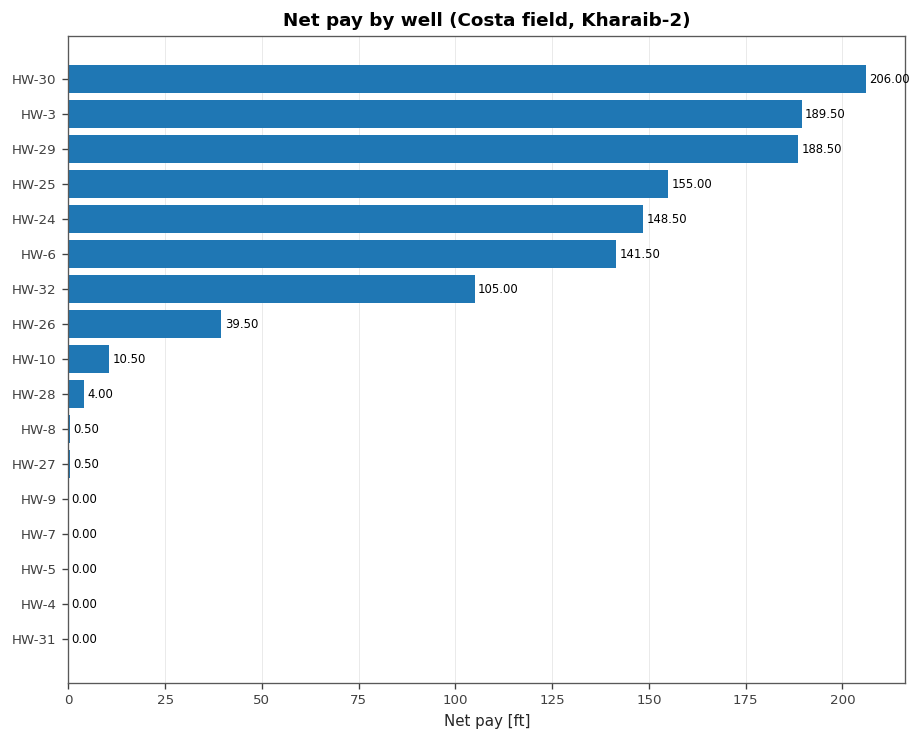

In [10]:
pp.bar_chart(portfolio["Well"], portfolio["Net Pay (ft)"], horizontal=True, sort_by=0,
             descending=True, value_labels=True, xlabel="Net pay [ft]",
             title="Net pay by well (Costa field, Kharaib-2)", figsize=(9, 7));

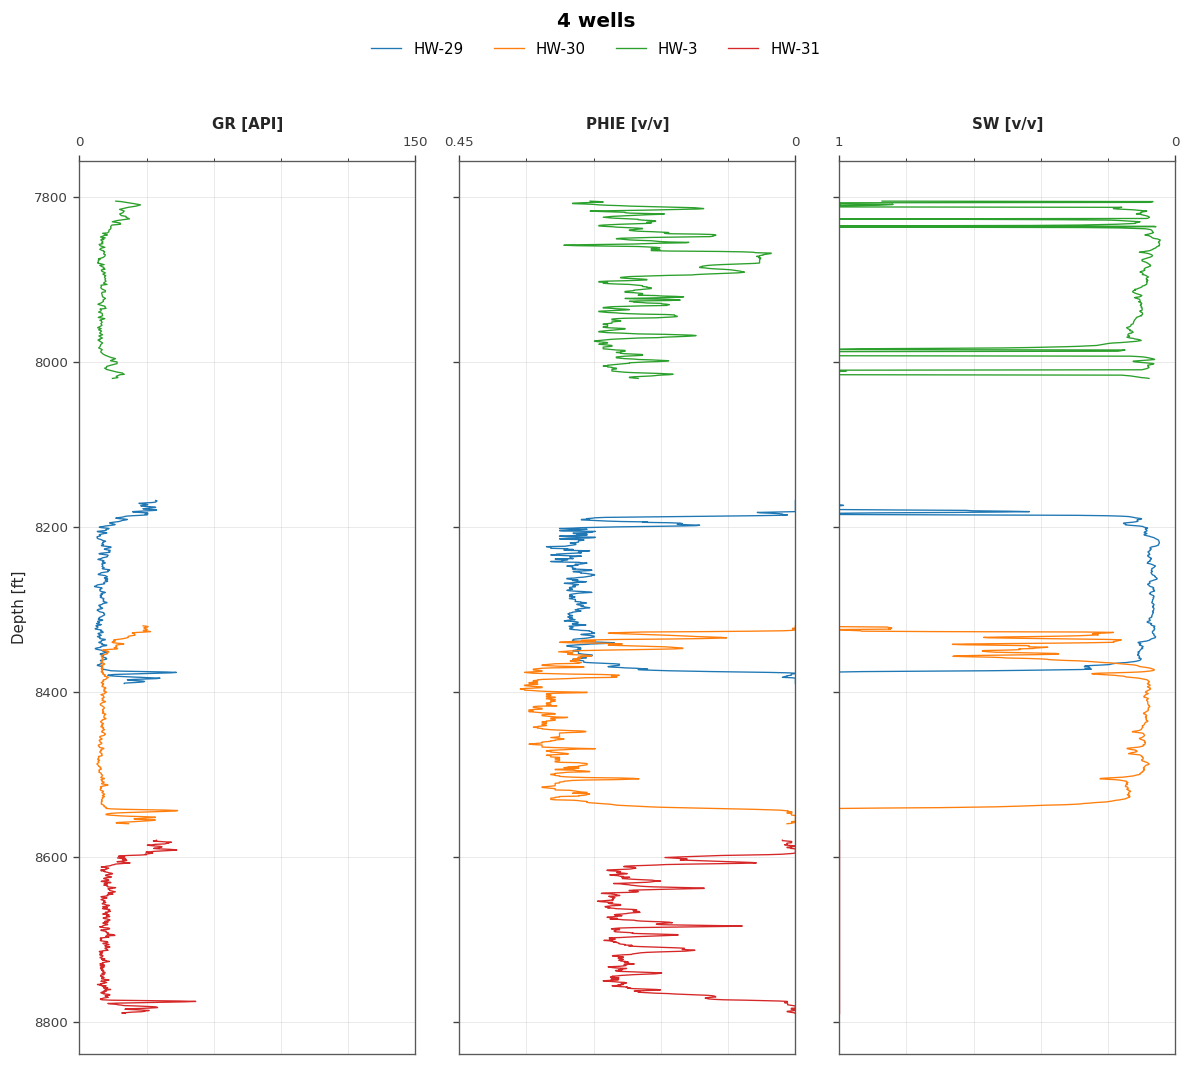

In [11]:
pp.plot([results[name] for name in ["HW-29", "HW-30", "HW-3", "HW-31"]], curves=["GR", "PHIE", "SW"],
        figsize=(10, 9)).show()

## Pitfalls & parameter choices

- **Read `failed`.** `pp.read` and `pp.interpret` on several wells keep going when one
  fails; `wells.failed` and `results.failed` name each failure with its reason, so a
  well missing from the table was skipped, not zero-pay.
- **`pp.interpret` works on copies.** The wells you read stay as read, so running the
  field a second time (with other cutoffs, say) starts from the same logs.
- **Each Costa file is the Kharaib-2 interval only.** Gross, Pay/Gross and net pay
  describe the logged Kharaib-2 interval, not the whole well; do not compare them with
  whole-well totals from other fields.
- **Normalize before pooling, not after computing.** Normalization is an input-conditioning
  step for cross-well comparison; do not normalize an already-interpreted output curve.
- **Same cutoffs, different recipe: expect deltas vs CS3.** Case study 3 screens
  this field with a hand-rolled chain (header Archie constants, Arps-corrected Rw) at the
  same cutoffs. Its per-well net pay differs somewhat from this run - that residual
  is the *recipe* (porosity chain, Archie constants), not the cutoffs.
- **Watch the depth unit.** Costa wells are in **feet**; net pay and HCPV inherit that
  unit. Do not mix them with metric (GeoLink) wells without converting.
- **Check permeability against core.** The default carbonate permeability sits at
  its 10,000 mD clip over most of the pay of HW-29, the top-ranked Costa well, far
  above the delivered `PERM_CC`; treat it as uncalibrated.
- **The HCPV index is relative.** `PHIE x (1 - Sw) x thickness` summed over pay is a
  per-unit-area screening indicator for ranking wells, not a volumetric reserve (no
  area, Bo, or recovery factor).

## Recap

- `pp.read` on a list of files and `pp.interpret` on the wells run the dynamic workflow
  across a whole field; `results.summary()` reports each well's status, net thickness and
  key results.
- **Log normalization** (`normalize_log`) removes acquisition drift so wells share one
  scale - the precondition for fair cross-well comparison, once you have checked that
  the shift is not geology.
- With the Kharaib-2 tops attached, `results.formation_summary()` yields per-well
  **net pay, average porosity/Sw, permeability and an HCPV index**, which sort into a
  portfolio table and sum to field totals. The default permeability needed a check
  against the files' `PERM_CC`: in the top-ranked well it is mostly clipped,
  uncalibrated output.
- **Cross-well summary plots** turn 17 analyses into one ranking and one log comparison
  that show where the pay and hydrocarbon volume concentrate.

## Try it yourself

> **Exercise 1.** Re-run the field with a stricter `phie_cutoff` in
> `pp.interpret(wells, ...)`. How does the total net pay respond, and which marginal
> wells drop out?
>
> **Exercise 2.** Replace the per-well GR normalization window with a **single field
> reference**: pass one well's P5 and P95 as `log_low` and `log_high` to `normalize_log`
> for every well. Does that change the ranking of borderline wells?
>
> **Exercise 3.** Chart each well's geometric-mean `PERM_CC` over its pay samples with
> `bar_chart` in HCPV order, beside the `Avg Perm (mD)` column. Do the
> highest-HCPV wells also have the best core-corrected permeability, and where does
> the default `PERM` change the picture?

## What's next

Continue with **19_llm_context_generation.ipynb**, which turns interpreted wells into
compact, auditable JSON context for LLM and review workflows. Lesson
**20_mcp_server.ipynb** then lets an LLM client drive the same workflow through the
Model Context Protocol. For a deeper look at this field, case studies 2 and 3 work
through Costa carbonate rock typing and a full 17-well screening.